![banner-pdi](https://user-images.githubusercontent.com/58775072/141189378-b5df3287-e8c0-48a1-ad11-825ba317463b.png)

## Universidade Federal de Campina Grande (UFCG)
## Centro de Engenharia Elétrica e Informática (CEEI) 
## Disciplina: Int. ao Processamento de Imagem Digital e Visão Computacional
## Professora: Luciana Ribeiro Veloso
## Aluno(a): Coloque seu nome aqui

# <span style="color:red">Laboratório 3.2: Domínio da Frequência e Filtragem</span>
***

## Observações
***

1. Os arquivos de laboratório devem ser salvos seguindo o seguinte padrão: `lab-x-nome-sobrenome.ipynb`.
2. Não esqueça de colocar o seu nome no cabeçalho acima.
3. Não altere a ordem das células e realize as implementações somente nos campos específicados.  
4. Ao longo do laboratório será solicitado perguntas teóricas relativas aos assuntos das aulas da disciplina e implementações de código utilizando a linguagem de programação Python. 
5. As células de implementação com código serão indicadas pelos seguintes comentários: `# IMPLEMENTE O SEU CÓDIGO AQUI`.
6. Para editar uma célula de texto, basta clicar duas vezes com o cursos do mouse para editar, e `Ctrl + Enter` para finalizar a edição. 
7. Para rodar as células com os códigos desenvolvidos, digite `Ctrl + Enter` ou clique em `Run` no menu do Jupyter.
8. Dúvidas, problemas de execução de código ou dificuldades com a linguagem de programação Python devem ser feitas durante as aulas de laboratório, encaminhadas para o grupo de WhatsApp da turma ou fórum do PVAE da disciplina.
9. Os laboratórios devem ser enviados nos campos especificados pelo PVAE. ATENTE-SE AOS PRAZOS DE ENTREGA!

### Importação dos Pacotes

In [1]:
import os                            # operational System para manipulação de arquivos.
import cv2                           # opencv para manipulação de imagens.
import numpy as np                   # numpy para manipulação de matrizes e arrays.
import matplotlib.pyplot as plt      # pyplot para plotagem de gráficos e imagens.
from scipy.signal import convolve2d  # scipy para realização de convoluções 2D.
import urllib.request as url         # urllib para baixar arquivos via HTTPS
import zipfile                       # zipfile para lidar com pastas compactadas

In [2]:
# baixando as imagens de referência
url.urlretrieve('https://github.com/Alyssonmach/pdi-labs/raw/main/imagens.zip', 'imagens.zip')
with zipfile.ZipFile('imagens.zip', 'r') as zip_ref:
    zip_ref.extractall('')

### Imagens no Domínio da Frequência

Uma imagem pode ser convertida do domínio espacial para o domínio da frequência através de várias transformadas, sendo uma delas a transformada de Fourier bidimensional. A FFT bidimensional está disponível no pacote Numpy, sendo geralmente utilizada em conjunto de uma função para deslocar o componente de frequência zero para o centro do arranjo bidimensional resultante. Naturalmente, a transformada inversa, IFFT, também está disponível.

* A FFT pode ser computada a partir de uma imagem por: **src_img_fft = np.fft.fft2( src_img )**
* A versão transladada da FFT pode ser obtida por: **shifted_fft = np.fft.fftshift( src_img_fft )**
* A IFFT pode ser obtida a partir de uma FFT com: **src_img = np.fft.ifft2( src_img_fft )**

 ## <span style='color:blue'>Questão 1: [Valor da Questão: 2.0][Taxa de acerto: x.x]</span>

* (a) O código abaixo utiliza as funções acima para misturar duas imagens:
    * Repita o processo para diferentes pares de imagens e comente como essa mistura é realizada.
    * Qual componente das misturas retém mais informações referentes à imagem original? Justifique.
* (b) A partir da imagem "tiger.jpg":
    * Calcule sua FFT e analise os valores do seu espectro.
    * Utilize a função fftshift para mover a origem da transformada para a região central e visualize novamente o espectro da FFT.
    * Aplique o logaritmo ao espectro para melhorar a visualização da imagem.
    * Calcule a IFFT da transformada após aplicar a translação. É possível reconhecer a imagem?

uint8


Text(0.5, 0, 'Shape: (512, 512)')

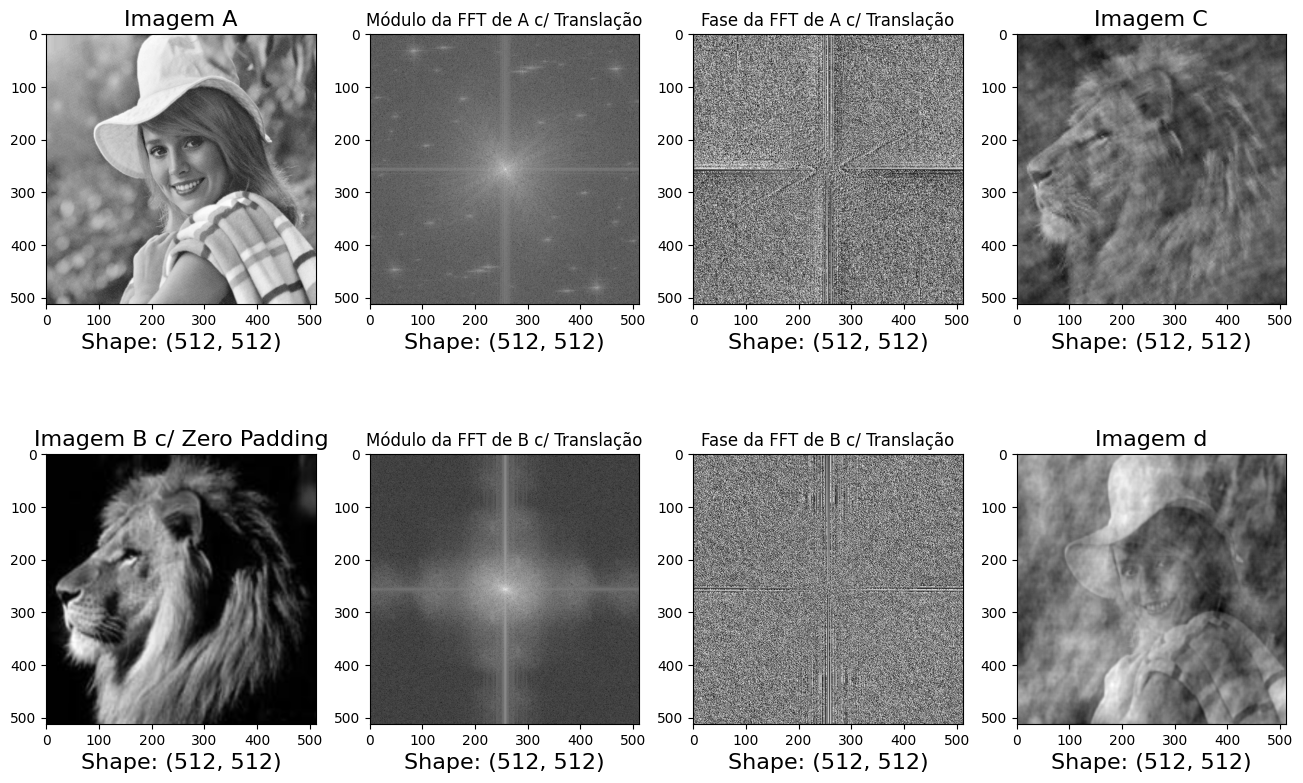

In [3]:
#  IMPLEMENTE SEU CÓDIGO AQUI -> QUESTÃO 1 - letra (a)
# carrega as imagens a e b como escala de cinza
imagem_a = cv2.imread("imagens/elaine.512.tiff", 0)
imagem_b = cv2.imread("imagens/leon.jpg", 0)

# redimenciona a imagem b para ter o mesmo tamanho da imagem a
im_b =cv2.resize(imagem_b, (imagem_a.shape[0], imagem_a.shape[1]))

# aplica a transformada rápida de fourier
fft_a = np.fft.fft2(imagem_a)
fft_b = np.fft.fft2(im_b)

# aplica translação às transformadas
fft_a_shift = np.fft.fftshift(fft_a)
fft_b_shift = np.fft.fftshift(fft_b)

# combina as imagens
fft_c = np.abs(fft_a) * np.exp(1j * np.angle(fft_b))
fft_d = np.abs(fft_b) * np.exp(1j * np.angle(fft_a))

# aplica a transformada inversa
imagem_c = np.fft.ifft2(fft_c).real
imagem_d = np.fft.ifft2(fft_d).real

imagem_c = (255 * ((imagem_c - np.min(imagem_c )) / np.max(imagem_c - np.min(imagem_c )))).astype(np.uint8)
print(imagem_c.dtype)

fig, axs = plt.subplots(nrows = 2, ncols = 4, figsize=(16, 10))

# primeira subfigura da primeira linha
axs[0][0].imshow(imagem_a, cmap="gray")
axs[0][0].set_title("Imagem A", fontsize = 16)
axs[0][0].set_xlabel("Shape: {}".format(imagem_a.shape), fontsize = 16)

# segunda subfigura da primeira linha
axs[0][1].imshow(np.log( np.abs(fft_a_shift)+1 ), cmap="gray")
axs[0][1].set_title("Módulo da FFT de A c/ Translação")
axs[0][1].set_xlabel("Shape: {}".format(fft_a_shift.shape), fontsize = 16)

# terceira subfigura da primeira linha
axs[0][2].imshow(np.angle(fft_a_shift), cmap="gray")
axs[0][2].set_title("Fase da FFT de A c/ Translação")
axs[0][2].set_xlabel("Shape: {}".format(imagem_a.shape), fontsize = 16)

# quarta subfigura da primeira linha
axs[0][3].imshow(imagem_c, cmap="gray")
axs[0][3].set_title("Imagem C", fontsize = 16)
axs[0][3].set_xlabel("Shape: {}".format(imagem_c.shape), fontsize = 16)

# primeira subfigura da segunda linha
axs[1][0].imshow(im_b, cmap="gray")
axs[1][0].set_title("Imagem B c/ Zero Padding", fontsize = 16)
axs[1][0].set_xlabel("Shape: {}".format(im_b.shape), fontsize = 16)

# segunda subfigura da segunda linha
axs[1][1].imshow(np.log( np.abs(fft_b_shift)+1 ), cmap="gray")
axs[1][1].set_title("Módulo da FFT de B c/ Translação")
axs[1][1].set_xlabel("Shape: {}".format(fft_b_shift.shape), fontsize = 16)

# terceira subfigura da segunda linha
axs[1][2].imshow(np.angle(fft_b_shift), cmap="gray")
axs[1][2].set_title("Fase da FFT de B c/ Translação")
axs[1][2].set_xlabel("Shape: {}".format(fft_b_shift.shape), fontsize = 16)

# quarta subfigura da segunda linha
axs[1][3].imshow(imagem_d, cmap="gray")
axs[1][3].set_title("Imagem d", fontsize = 16)
axs[1][3].set_xlabel("Shape: {}".format(imagem_d.shape), fontsize = 16)

Text(0.5, 0, 'Shape: (227, 281)')

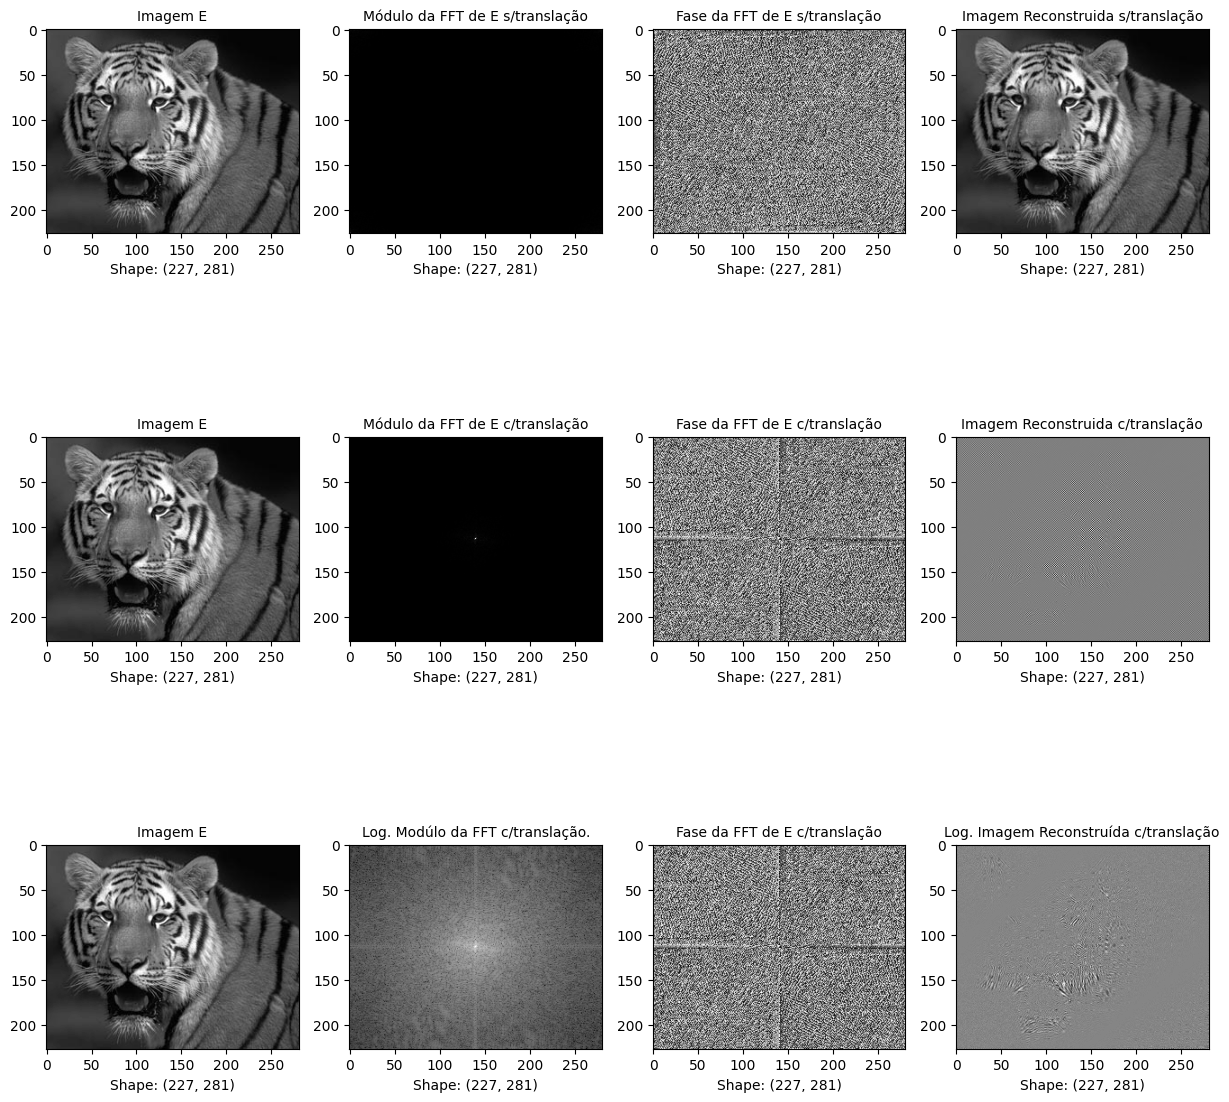

In [4]:
#  IMPLEMENTE SEU CÓDIGO AQUI -> QUESTÃO 1 - LETRA (b)
imagem_e = cv2.imread('imagens/tiger.jpg', 0)

fft_e = np.fft.fft2(imagem_e)
fft_e_shift = np.fft.fftshift(fft_e)

fft_e_re = np.abs(fft_e) * np.exp(1j * np.angle(fft_e))
imagem_e_re = np.fft.ifft2(fft_e_re).real

fft_e_shift_re = np.abs(fft_e_shift) * np.exp(1j * np.angle(fft_e_shift))
imagem_e_shift_re = np.fft.ifft2(fft_e_shift_re).real
imagem_e_shift_re = (255*((imagem_e_shift_re - np.min(imagem_e_shift_re )) / np.max(imagem_e_shift_re - np.min(imagem_e_shift_re)))).astype(np.uint8)

fft_e_shift_re = np.abs(fft_e_shift) * np.exp(1j * np.angle(fft_e_shift))
imagem_e_shift_re = np.fft.ifft2(fft_e_shift_re).real
imagem_e_shift_re = (255*((imagem_e_shift_re - np.min(imagem_e_shift_re )) / np.max(imagem_e_shift_re - np.min(imagem_e_shift_re)))).astype(np.uint8)

fft_e_shift_re_log = np.log(np.abs(fft_e_shift)+1) * np.exp(1j * np.angle(fft_e_shift))
imagem_e_shift_re_log = np.fft.ifft2(fft_e_shift_re_log).real
imagem_e_shift_re_log = (255*((imagem_e_shift_re_log - np.min(imagem_e_shift_re_log )) / np.max(imagem_e_shift_re_log - np.min(imagem_e_shift_re_log)))).astype(np.uint8)

fft_real = np.fft.ifft2(fft_e.real).real
fft_e2x = np.fft.fft2(fft_e.real).real

fft_e_shift2x = np.fft.fftshift(fft_e_shift)
fft_e_shift2x = np.abs(fft_e_shift2x) * np.exp(1j * np.angle(fft_e_shift2x))
imagem_e_shift2x_re = np.fft.ifft2(fft_e_shift2x).real


fig, axs = plt.subplots(nrows = 3, ncols = 4, figsize=(15, 15))

# primeira subfigura da primeira linha
axs[0,0].imshow(imagem_e, cmap="gray")
axs[0,0].set_title("Imagem E", fontsize = 10)
axs[0,0].set_xlabel("Shape: {}".format(imagem_e.shape), fontsize = 10)

# segunda subfigura da primeira linha
axs[0,1].imshow(np.abs(fft_e), cmap="gray")
axs[0,1].set_title("Módulo da FFT de E s/translação", fontsize = 10)
axs[0,1].set_xlabel("Shape: {}".format(fft_e.shape), fontsize = 10)

# terceira subfigura da primeira linha
axs[0,2].imshow(np.angle(fft_e), cmap="gray")
axs[0,2].set_title("Fase da FFT de E s/translação", fontsize = 10)
axs[0,2].set_xlabel("Shape: {}".format(fft_e.shape), fontsize = 10) 

# quarta subfigura da primeira linha 
axs[0,3].imshow(imagem_e_re, cmap="gray")
axs[0,3].set_title("Imagem Reconstruida s/translação", fontsize = 10)
axs[0,3].set_xlabel("Shape: {}".format(imagem_e_re.shape), fontsize = 10) 

# primeira subfigura da segunda linha
axs[1,0].imshow(imagem_e, cmap="gray") 
axs[1,0].set_title("Imagem E", fontsize = 10)
axs[1,0].set_xlabel("Shape: {}".format(imagem_e.shape), fontsize = 10)

# segunda subfigura da segunda linha
axs[1,1].imshow(np.abs(fft_e_shift), cmap="gray")
axs[1,1].set_title("Módulo da FFT de E c/translação", fontsize = 10)
axs[1,1].set_xlabel("Shape: {}".format(fft_e.shape), fontsize = 10)

# terceira subfigura da segunda linha  
axs[1,2].imshow(np.angle(fft_e_shift), cmap="gray")
axs[1,2].set_title("Fase da FFT de E c/translação", fontsize = 10)
axs[1,2].set_xlabel("Shape: {}".format(fft_e_shift.shape), fontsize = 10)

# quarta subfigura da primeira linha 
axs[1,3].imshow(imagem_e_shift_re, cmap="gray")
axs[1,3].set_title("Imagem Reconstruida c/translação", fontsize = 10)
axs[1,3].set_xlabel("Shape: {}".format(imagem_e_shift_re.shape), fontsize = 10) 

# primeira subfigura da terceira linha
axs[2,0].imshow(imagem_e, cmap="gray") 
axs[2,0].set_title("Imagem E", fontsize = 10)
axs[2,0].set_xlabel("Shape: {}".format(imagem_e.shape), fontsize = 10)

# segunda subfigura da terceira linha  
axs[2,1].imshow(np.log(np.abs(fft_e_shift)+1), cmap="gray")
axs[2,1].set_title("Log. Modúlo da FFT c/translação.", fontsize = 10)
axs[2,1].set_xlabel("Shape: {}".format(fft_e_shift.shape), fontsize = 10)

# terceira subfigura da terceira linha   
axs[2,2].imshow(np.angle(fft_e_shift), cmap="gray")
axs[2,2].set_title("Fase da FFT de E c/translação", fontsize = 10)
axs[2,2].set_xlabel("Shape: {}".format(fft_e_shift.shape), fontsize = 10)

# quarta subfigura da terceira linha   
axs[2,3].imshow(imagem_e_shift_re_log, cmap="gray")
axs[2,3].set_title("Log. Imagem Reconstruída c/translação", fontsize = 10)
axs[2,3].set_xlabel("Shape: {}".format(imagem_e_shift_re_log.shape), fontsize = 10)

## <span style='color:green'>Respostas da Questão 1:</span>

* (a) Ao plotar o espectro e a fase da FFT da imagem sem aplicar a translação, é possível observar que o espectro é pouco esbranquiçado nas bordas, indicando que é uma cor não muito presente na imagem. Nesse caso, a imagem tende uma menor baixa frequência. Além disso, o cálculo da inversa da FFT da imagem permite reconstruir a imagem orignal. Ao plotar o espectro e a fase da FFT da imagem aplicando a translação, é possível observar que o espectro é pouco esbranquiçado no centro, o que possibilita ter uma melhor visualização sobre o que foi apontado na primeira observação. Entretanto, não foi possível realizar a reconstrução na imagem após o espectro e a fase serem transladados. 
* (b) A aplicação da transformação logarítmica na imagem permitiu acentuar detalhes não visíveis na imagem. Entretanto, pouco contribuiu com a visulização da imagem reconstruida utilizando o espectro e a fase transladada da imagem. 

### Filtragem em Frequência

Conforme visto nas aulas de PDI, imagens também podem ser filtradas no domínio da frequência utilizando FFT, uma abordagem mais condizente com o termo "filtragem". Para realizar a filtragem, é necessário realizar os seguintes passos:

1. Obter os parâmetros de preenchimento Mp e Np. 
2. Realizar o preenchimento da imagem de entrada.
3. Calcular a FFT da imagem de entrada.
4. Aplicar a translação para centralizar a transformada da imagem.
5. Realizar o preenchimento do filtro utilizado.
6. Calcular a FFT do filtro utilizado.
7. Aplicar a translação para centralizar a transformada do filtro.
8. Obter a FFT da imagem filtrada a partir do produto entre as FFTs da imagem e do filtro.
9. Desfazer a translação e realizar a transformada inversa.

Esse procedimento é realizado nas duas células a seguir, em que a primeira célula define algumas funções auxiliares e a segunda realiza a filtragem em frequência e a filtragem no espaço para que se possa comparar os resultados.

In [5]:
# essa célula contém funções auxiliares para a realização da filtragem em frequência.
def get_2d_gaussian_kernel(size, sigma, dtype = cv2.CV_32F):
    '''essa função retorna um filtro gaussiano 2d com base no tamanho e sgima especificados.'''
    
    # produz filtros 1d nas direções x e y
    kernel_y = cv2.getGaussianKernel(size, sigma, ktype = dtype)
    kernel_x = cv2.getGaussianKernel(size, sigma, ktype = dtype).T
    
    # retorna o produto matricial dos filtros para produzir um filtro 2d
    return np.dot( kernel_y, kernel_x )

def paddedsize(src_img, kernel):
    '''essa função determina o menor tamanho apropriado para a realização da 
    filtragem em frequência a partir de uma imagem (scr_img) e um filtro (kernel)'''
    
    # extrai as dimensões da imagem e do filtro
    H_i, W_i = src_img.shape
    H_k, W_k = kernel.shape
    
    # encontra o menor tamanho que satisfaz as condições de filtragem
    H = H_i + H_k -1
    W = W_i + W_k -1
    
    # ajusta H e W para que sejam pares
    H = (H+1) if H % 2 != 0 else H
    W = (W+1) if W % 2 != 0 else W
    
    return H, W

def apply_padding(img, shape, dtype):
    '''essa função aplica zero-padding em uma imagem com base no shape fornecido'''
    
    padded = np.zeros(shape, dtype)
    padded[:img.shape[0], :img.shape[1]] = img
    
    return padded

 ## <span style='color:blue'>Questão 2: [Valor da Questão: 2.0][Taxa de acerto: x.x]</span>
 
* O código abaixo realiza a filtragem a partir de um filtro passa-baixas Gaussiano:
    * (a) Que elementos na FFT do filtro permitem identificar que se trata de um filtro passa-baixas?
    * (b) Ajuste o tamanho do filtro a partir da variável ksize e comente o que acontece com o módulo da sua FFT.

Text(0.5, 0, 'Shape: (518, 518)')

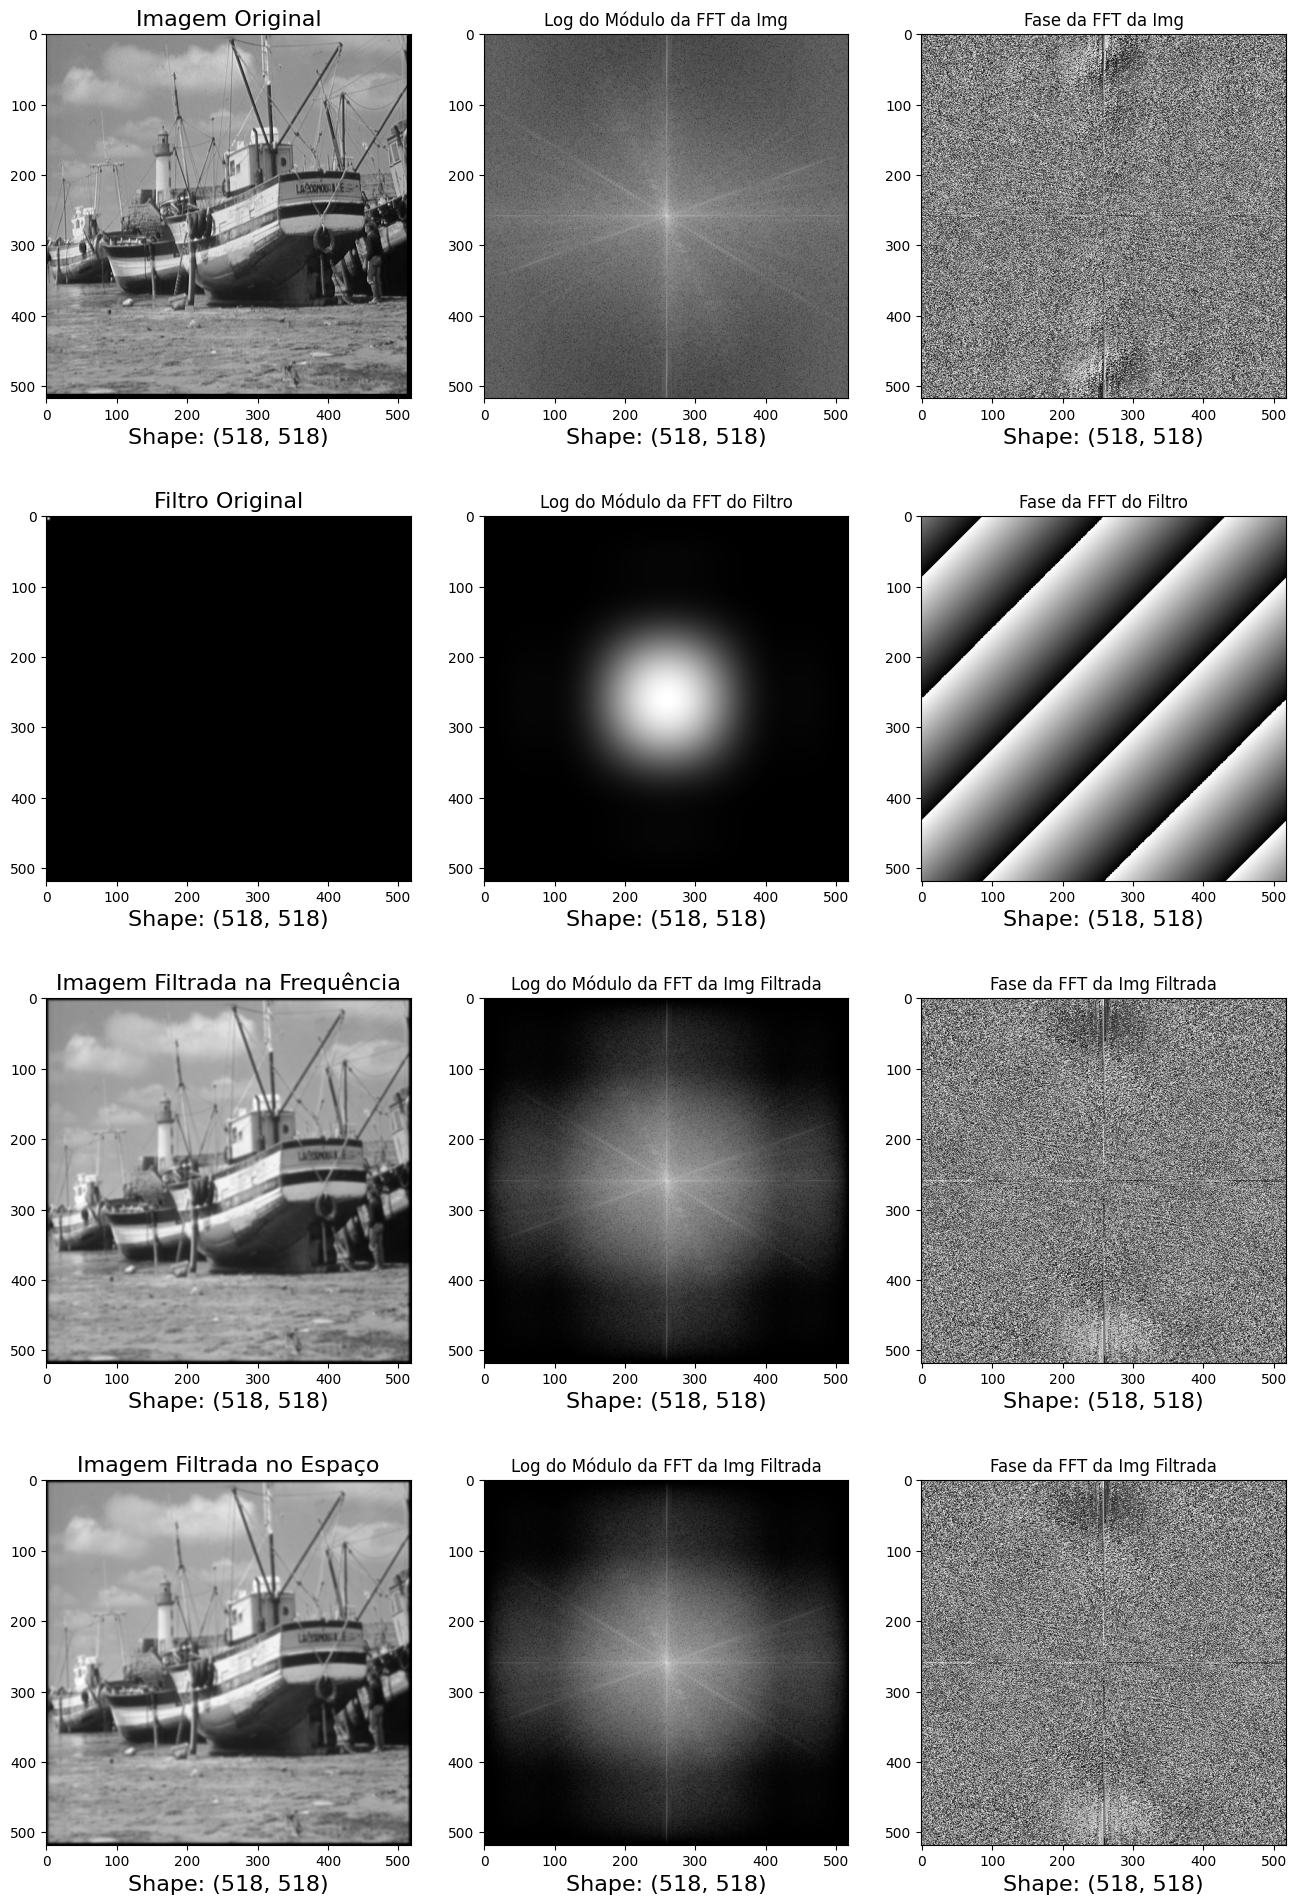

In [6]:
# imagem a ser filtrada
src_img  = cv2.imread('imagens/boat.512.tiff', 0)

# filtro utilizado
sigma  = 0
ksize  = 7
kernel = get_2d_gaussian_kernel( ksize, sigma)

# Encontra o tamanho minimo das imagens
H, W = paddedsize(src_img, kernel)

# aplica padding na imagem e no filtro
pad_img = apply_padding(src_img, (H, W), np.float64)
pad_knl = apply_padding(kernel,  (H, W), np.float64)

# aplica a transformada
img_fft = np.fft.fft2( pad_img )
knl_fft = np.fft.fft2( pad_knl )

# aplica translação para centralizar a imagem
img_shift = np.fft.fftshift( img_fft )
knl_shift = np.fft.fftshift( knl_fft )

# multiplica para realizar a filtragem
dst_shift = img_shift * knl_shift

# desfaz a translação e obtém a imagem correspondente no domínio do tempo a partir da IFFT
dst_fft = np.fft.ifftshift( dst_shift )
frq_dst_img = np.fft.ifft2( dst_fft ).real

# filtragem no espaço
spa_dst_img  = convolve2d( src_img, kernel, mode = "full", boundary = "fill", fillvalue = 0).astype(np.float64)

# FFT para obter a resposta em frequência da convolução no espaço
pad_spa_dst_img   = apply_padding(spa_dst_img, (H, W), np.float64)
spa_dst_img_fft   = np.fft.fft2( pad_spa_dst_img )
spa_dst_img_shift = np.fft.fftshift( spa_dst_img_fft )

fig, axs = plt.subplots(nrows = 4, ncols = 3, figsize = (16, 24))

axs[0][0].imshow(pad_img, cmap = "gray")
axs[0][0].set_title("Imagem Original", fontsize = 16)
axs[0][0].set_xlabel("Shape: {}".format(pad_img.shape), fontsize = 16)

axs[0][1].imshow( np.log(np.abs(img_shift)+1) , cmap = "gray")
axs[0][1].set_title("Log do Módulo da FFT da Img")
axs[0][1].set_xlabel("Shape: {}".format(img_shift.shape), fontsize = 16)

axs[0][2].imshow(np.angle(img_shift), cmap = "gray")
axs[0][2].set_title("Fase da FFT da Img")
axs[0][2].set_xlabel("Shape: {}".format(img_shift.shape), fontsize = 16)

axs[1][0].imshow(pad_knl, cmap="gray")
axs[1][0].set_title("Filtro Original", fontsize = 16)
axs[1][0].set_xlabel("Shape: {}".format(pad_knl.shape), fontsize = 16)

axs[1][1].imshow( np.log(np.abs(knl_shift)+1) , cmap = "gray")
axs[1][1].set_title("Log do Módulo da FFT do Filtro")
axs[1][1].set_xlabel("Shape: {}".format(knl_shift.shape), fontsize = 16)

axs[1][2].imshow(np.angle(knl_shift), cmap = "gray")
axs[1][2].set_title("Fase da FFT do Filtro")
axs[1][2].set_xlabel("Shape: {}".format(knl_shift.shape), fontsize = 16)

axs[2][0].imshow(frq_dst_img, cmap = "gray")
axs[2][0].set_title("Imagem Filtrada na Frequência", fontsize = 16)
axs[2][0].set_xlabel("Shape: {}".format(frq_dst_img.shape), fontsize = 16)

axs[2][1].imshow( np.log(np.abs(dst_shift)+1) , cmap = "gray")
axs[2][1].set_title("Log do Módulo da FFT da Img Filtrada")
axs[2][1].set_xlabel("Shape: {}".format(dst_shift.shape), fontsize = 16)

axs[2][2].imshow(np.angle(dst_shift), cmap = "gray")
axs[2][2].set_title("Fase da FFT da Img Filtrada")
axs[2][2].set_xlabel("Shape: {}".format(dst_shift.shape), fontsize = 16)

axs[3][0].imshow(spa_dst_img, cmap = "gray")
axs[3][0].set_title("Imagem Filtrada no Espaço", fontsize = 16)
axs[3][0].set_xlabel("Shape: {}".format(spa_dst_img.shape), fontsize = 16)

axs[3][1].imshow( np.log(np.abs(spa_dst_img_shift)+1) , cmap = "gray")
axs[3][1].set_title("Log do Módulo da FFT da Img Filtrada")
axs[3][1].set_xlabel("Shape: {}".format(spa_dst_img_shift.shape), fontsize = 16)

axs[3][2].imshow(np.angle(spa_dst_img_shift), cmap = "gray")
axs[3][2].set_title("Fase da FFT da Img Filtrada")
axs[3][2].set_xlabel("Shape: {}".format(spa_dst_img_shift.shape), fontsize = 16)

## <span style='color:green'>Respostas da Questão 2:</span>

* (a) O log do módulo da FFT do filtro nos mostra que existe uma região considerável de pixels brancos (alta intensidade) concentrados no centro dessa imagem. Desse modo, isso indica que é um filtro de baixa frequência, justificando o porquê do filtro ser denominado como passa-baixa.
* (b) Um aumento no parâmetro ksize diminuiu a região esbranquiçada do módulo da FFT do filtro, ao passo em que uma diminuição nesse parâmetro aumento essa região.

* **Observe que a filtragem em frequência foi equivalente a uma filtragem espacial utilizando convoluções do tipo "full", o que resulta em uma borda escura em torno da imagem de saída e de uma imagem de saída pouco maior que a imagem de entrada.**
* **Se quiséssemos uma convolução do tipo "same" ou "valid", bastaria recortar a imagem de saída para eliminar elementos da borda e obteríamos imagens idênticas.**

## <span style='color:blue'>Questão 3: [Valor da Questão: 2.0][Taxa de acerto: x.x]</span>

* O código abaixo ilustra a magnitude da FFT de diversos filtros. Classifique-os em filtros passa-baixas e filtros passa-altas. Justifique.

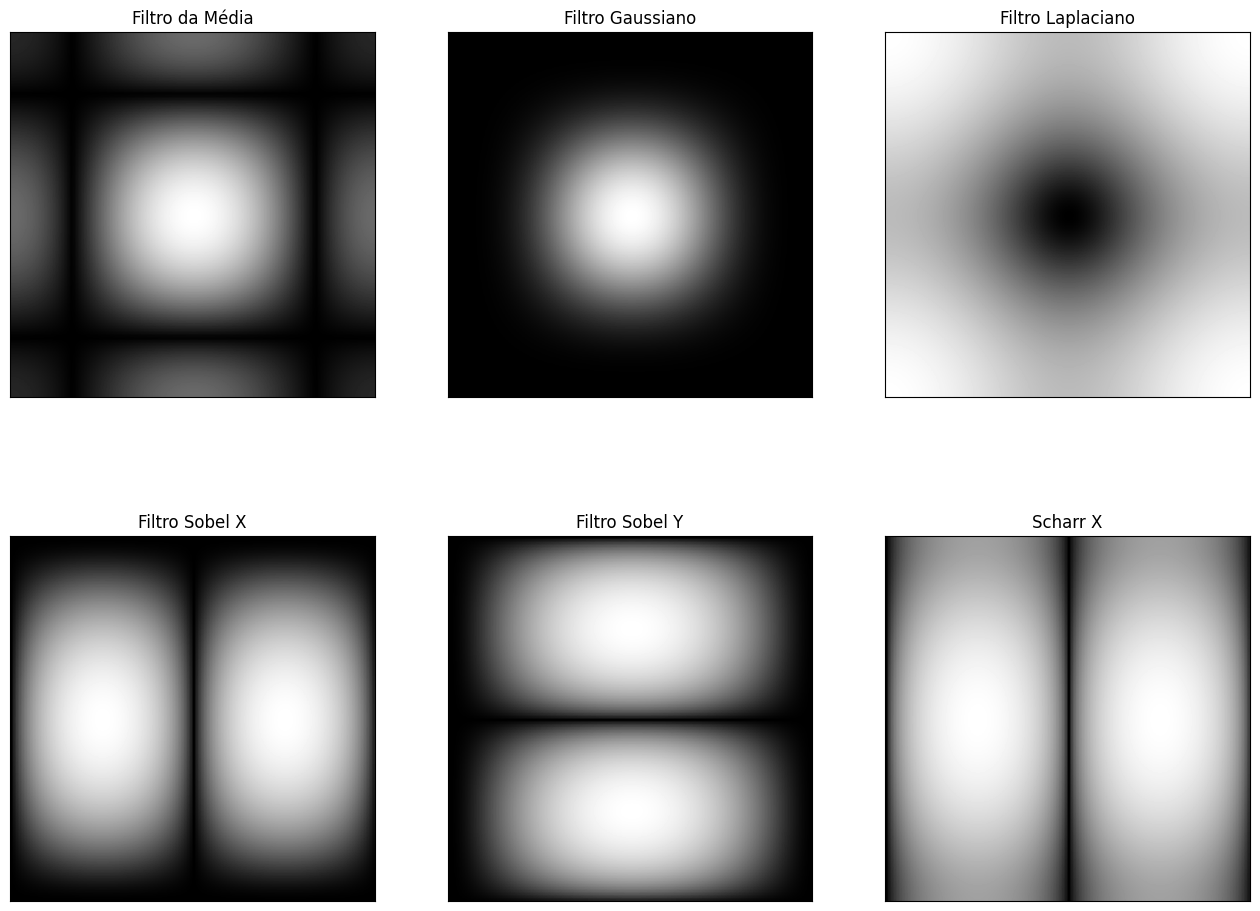

In [7]:
# filtro da média
mean_filter = np.ones((3, 3)) / 9

# filtro gaussiano
gauss_filter = get_2d_gaussian_kernel(5, 0)

# filtros de detecção de borda
# scharr in x-direction
scharr_filter = np.array([[-3, 0, 3], [-10,0,10], [-3, 0, 3]])

# sobel in x direction
sobel_x = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]])

# sobel in y direction
sobel_y = np.array([[-1,-2,-1], [0, 0, 0], [1, 2, 1]])

# laplacian
laplacian =np.array([[0, 1, 0], [1,-4, 1], [0, 1, 0]])

# lista os filtros
filters = [mean_filter, gauss_filter, laplacian, sobel_x, sobel_y, scharr_filter]

# lista os nomes dos filtros
filter_name = ["Filtro da Média", "Filtro Gaussiano","Filtro Laplaciano", "Filtro Sobel X", "Filtro Sobel Y", "Scharr X"]

# computa a FFT dos filtros da lista
fft_filters = [np.fft.fft2(x, (128,128)) for x in filters]

# aplica fftshift na FFT de cada filtro
fft_shift = [np.fft.fftshift(y) for y in fft_filters]

# obtém a magnitude da FFT de cada filtro
mag_spectrum = [np.log(np.abs(z)+1) for z in fft_shift]

fig, axs = plt.subplots(nrows = 2, ncols = 3, figsize=(16, 12))

# Plota todos os filtros
for i, ax in enumerate(axs.flat):
    plt.sca(ax)
    plt.imshow(mag_spectrum[i], cmap = 'gray')
    plt.title(filter_name[i]), plt.xticks([]), plt.yticks([])

## <span style='color:green'>Respostas da Questão 3:</span>

* Filtro passa-baixa (região mais esbranquiçada (alta intensidade) no centro do espectro transladado):
    * Filtro da Média;
    * Filtro Gaussiano;
    
* Filtro passa-alta (região mais escura (baixa intensidade) no centro do espectro transladado):
    * Filtro Laplaciano;
    * Filtro Sobel X;
    * Filtro Sobrel y;
    * Filtro Scharr X;

 ## <span style='color:blue'>Questão 4: [Valor da Questão: 2.0][Taxa de acerto: x.x]</span>

* Substitua no código abaixo kernel pelos filtros acima e teste os resultados. Utilize quantas células for necessário.

Text(0.5, 0, 'Shape: (514, 514)')

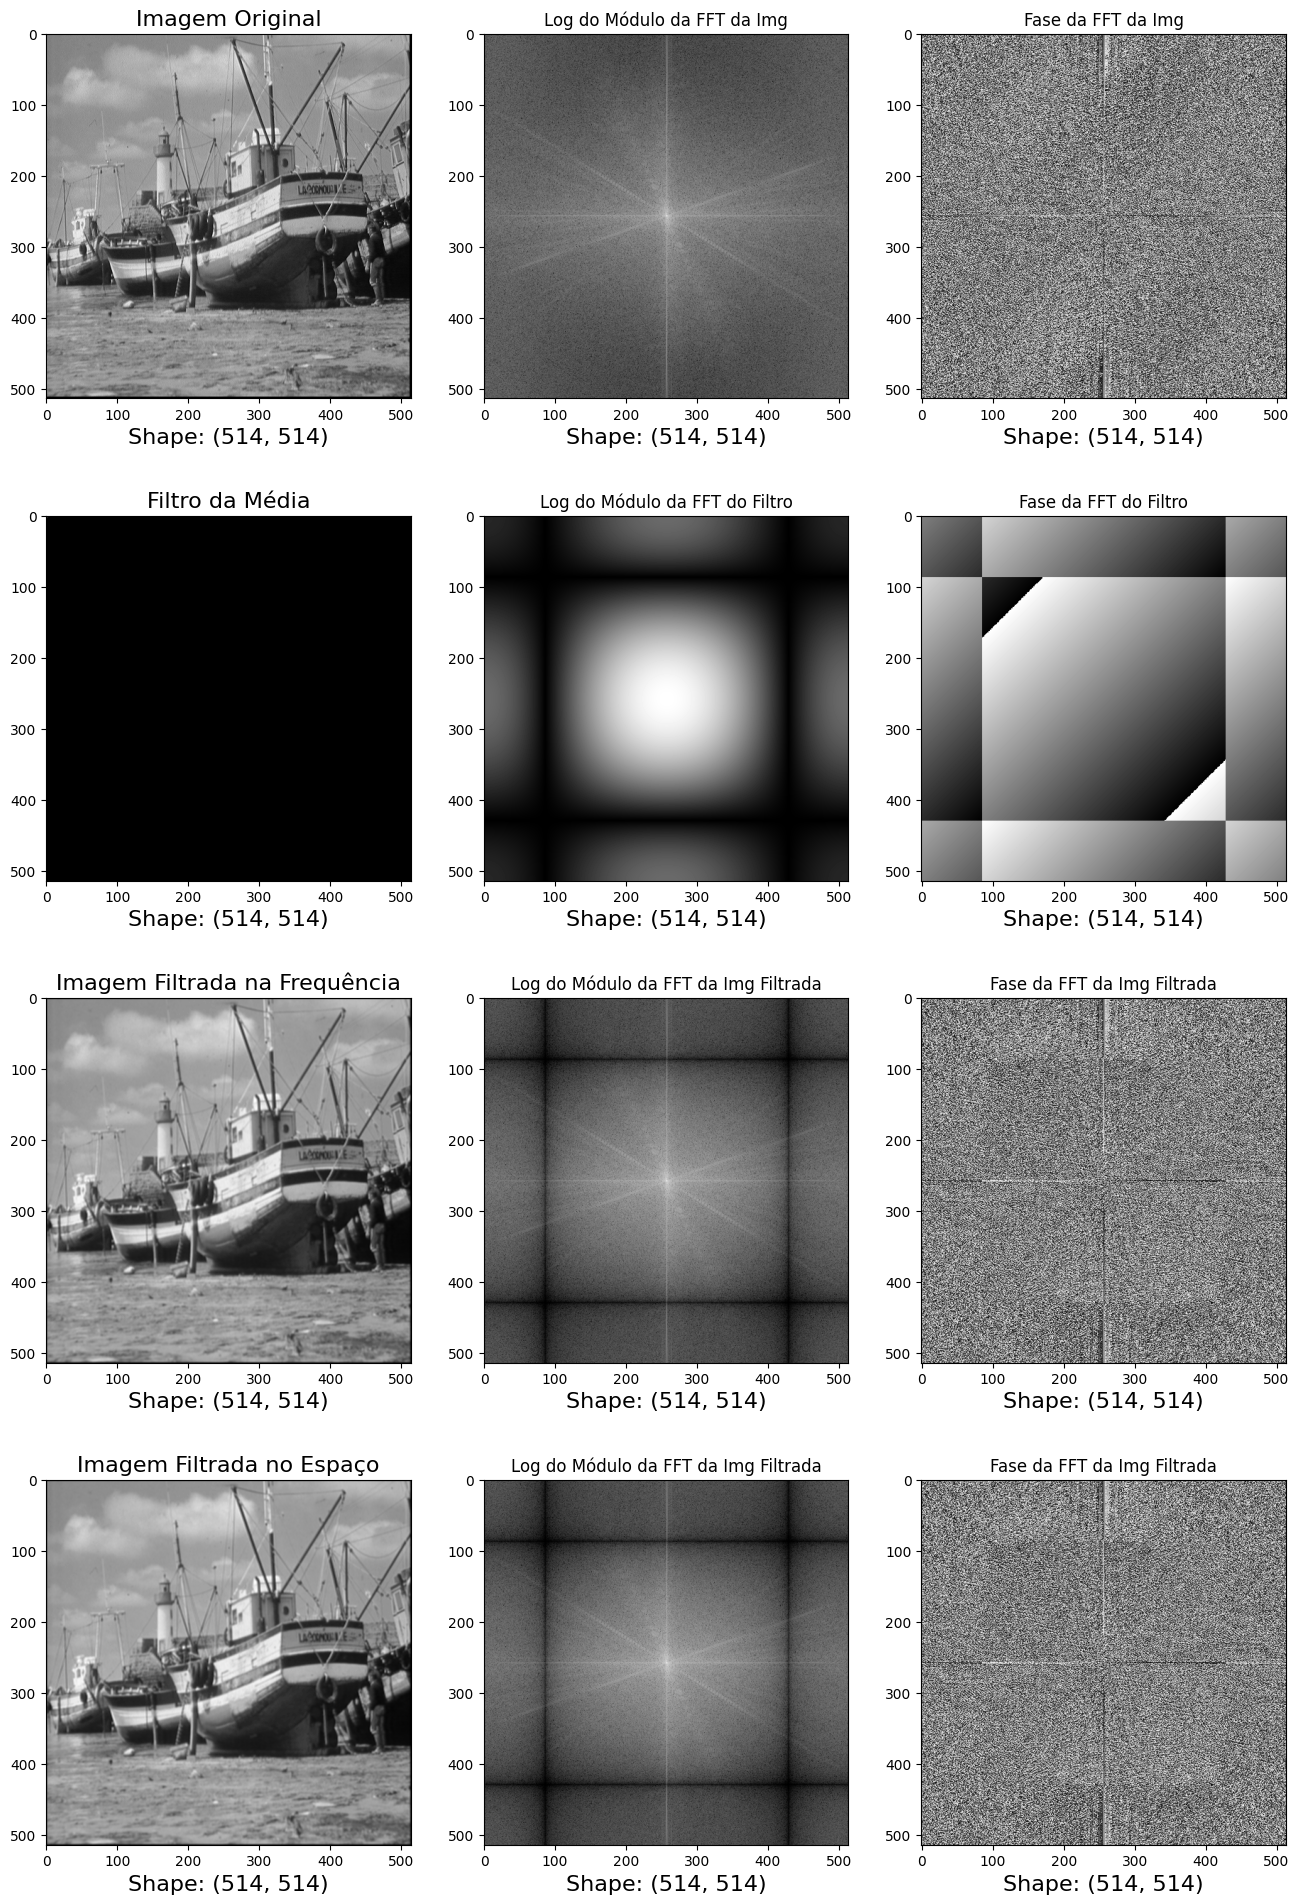

In [8]:
# SUBSTITUA OS FILTROS AQUI --> QUESTÃO 4 
# imagem a ser filtrada
src_img  = cv2.imread("imagens/boat.512.tiff", 0 )
 
# filtro utilizado
kernel = mean_filter # adicione o filtro aqui

# encontra o tamanho minimo das imagens
H, W = paddedsize(src_img, kernel)

# aplica padding na imagem e no filtro
pad_img = apply_padding(src_img, (H, W), np.float64)
pad_knl = apply_padding(kernel,  (H, W), np.float64)

# aplica a transformada
img_fft = np.fft.fft2(pad_img)
knl_fft = np.fft.fft2(pad_knl)

# aplica translação para centralizar a imagem
img_shift = np.fft.fftshift(img_fft)
knl_shift = np.fft.fftshift(knl_fft)

# multiplica para realizar a filtragem
dst_shift = img_shift * knl_shift

# desfaz a translação e obtém a imagem correspondente no domínio do tempo a partir da IFFT
dst_fft = np.fft.ifftshift(dst_shift)
frq_dst_img = np.fft.ifft2(dst_fft ).real

# filtragem no espaço
spa_dst_img  = convolve2d(src_img, kernel, mode = "full", boundary = "fill", fillvalue = 0).astype(np.float64)

# FFT para obter a resposta em frequência da convolução no espaço
pad_spa_dst_img   = apply_padding(spa_dst_img, (H, W), np.float64)
spa_dst_img_fft   = np.fft.fft2( pad_spa_dst_img )
spa_dst_img_shift = np.fft.fftshift( spa_dst_img_fft )

fig, axs = plt.subplots(nrows = 4, ncols = 3, figsize=(16, 24))

axs[0][0].imshow(pad_img, cmap="gray")
axs[0][0].set_title("Imagem Original", fontsize = 16)
axs[0][0].set_xlabel("Shape: {}".format(pad_img.shape), fontsize = 16)

axs[0][1].imshow( np.log(np.abs(img_shift)+1) , cmap="gray" )
axs[0][1].set_title("Log do Módulo da FFT da Img")
axs[0][1].set_xlabel("Shape: {}".format(img_shift.shape), fontsize = 16)

axs[0][2].imshow(np.angle(img_shift), cmap="gray")
axs[0][2].set_title("Fase da FFT da Img")
axs[0][2].set_xlabel("Shape: {}".format(img_shift.shape), fontsize = 16)

axs[1][0].imshow(pad_knl, vmin=0, vmax=1, cmap="gray")
axs[1][0].set_title("Filtro da Média", fontsize = 16)
axs[1][0].set_xlabel("Shape: {}".format(pad_knl.shape), fontsize = 16)

axs[1][1].imshow( np.log(np.abs(knl_shift)+1) , cmap="gray" )
axs[1][1].set_title("Log do Módulo da FFT do Filtro")
axs[1][1].set_xlabel("Shape: {}".format(knl_shift.shape), fontsize = 16)

axs[1][2].imshow(np.angle(knl_shift), cmap="gray")
axs[1][2].set_title("Fase da FFT do Filtro")
axs[1][2].set_xlabel("Shape: {}".format(knl_shift.shape), fontsize = 16)

axs[2][0].imshow(frq_dst_img, cmap="gray")
axs[2][0].set_title("Imagem Filtrada na Frequência", fontsize = 16)
axs[2][0].set_xlabel("Shape: {}".format(frq_dst_img.shape), fontsize = 16)

axs[2][1].imshow( np.log(np.abs(dst_shift)+1) , cmap="gray" )
axs[2][1].set_title("Log do Módulo da FFT da Img Filtrada")
axs[2][1].set_xlabel("Shape: {}".format(dst_shift.shape), fontsize = 16)

axs[2][2].imshow(np.angle(dst_shift), cmap="gray")
axs[2][2].set_title("Fase da FFT da Img Filtrada")
axs[2][2].set_xlabel("Shape: {}".format(dst_shift.shape), fontsize = 16)

axs[3][0].imshow(spa_dst_img, cmap="gray")
axs[3][0].set_title("Imagem Filtrada no Espaço", fontsize = 16)
axs[3][0].set_xlabel("Shape: {}".format(spa_dst_img.shape), fontsize = 16)

axs[3][1].imshow( np.log(np.abs(spa_dst_img_shift)+1) , cmap="gray" )
axs[3][1].set_title("Log do Módulo da FFT da Img Filtrada")
axs[3][1].set_xlabel("Shape: {}".format(spa_dst_img_shift.shape), fontsize = 16)

axs[3][2].imshow(np.angle(spa_dst_img_shift), cmap="gray")
axs[3][2].set_title("Fase da FFT da Img Filtrada")
axs[3][2].set_xlabel("Shape: {}".format(spa_dst_img_shift.shape), fontsize = 16)

### Tempo de processamento

Observe que o tamanho dos filtros é uma variável de baixo impacto no número de operações realizado na filtragem em frequência, o que não pode ser dito para a filtragem no espaço. Para medir o impacto desse fenômeno sobre o tempo de execução dos algoritmos, as células abaixo utilizam a mágica **%%timeit**, que computa o tempo médio de execução de uma célula.

In [9]:
def freq_filt(src_img, kernel):
    '''essa função realiza a filtragem em frequência a partir de uma imagem (src_img) e um filtro (kernel).'''
    
    # encontra o tamanho minimo das imagens
    H, W = paddedsize(src_img, kernel)
    
    # aplica padding na imagem e no filtro
    pad_img = apply_padding(src_img, (H, W), np.float64)
    pad_knl = apply_padding(kernel, (H, W), np.float64)
    
    # aplica a transformada
    img_fft = np.fft.fft2(pad_img)
    knl_fft = np.fft.fft2(pad_knl)
    
    # aplica translação para centralizar a imagem
    img_shift = np.fft.fftshift(img_fft)
    knl_shift = np.fft.fftshift(knl_fft)
    
    # multiplica para realizar a filtragem
    dst_shift = img_shift * knl_shift
    
    # desfaz a translação
    dst_fft = np.fft.ifftshift(dst_shift)
    dst_img = np.fft.ifft2(dst_fft).real
    
    return dst_img

 ## <span style='color:blue'>Questão 5: [Valor da Questão: 2.0][Taxa de acerto: x.x]</span>
* Execute as células abaixo utilizando filtros de lado 3, 7, 11 e 25 e comente os resultados observados.

In [10]:
ksize = 3
sigma = 0
kernel = get_2d_gaussian_kernel( ksize, sigma )
lenna = cv2.imread("imagens/lenna.tif", 0 )
print("lenna.shape:", lenna.shape)

lenna.shape: (256, 256)


In [11]:
%%timeit
output = convolve2d( lenna, kernel, mode="full", boundary="fill", fillvalue=0 ).astype(np.float64)

2.24 ms ± 227 µs per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [12]:
%%timeit
output = freq_filt( lenna, kernel )

16.2 ms ± 892 µs per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [13]:
ksize = 7
sigma = 0
kernel = get_2d_gaussian_kernel( ksize, sigma)
lenna = cv2.imread("imagens/lenna.tif", 0)
print("lenna.shape:", lenna.shape)

lenna.shape: (256, 256)


In [14]:
%%timeit
output = convolve2d( lenna, kernel, mode="full", boundary="fill", fillvalue=0 ).astype(np.float64)

8.23 ms ± 403 µs per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [15]:
%%timeit
output = freq_filt( lenna, kernel )

26.9 ms ± 1.05 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [16]:
ksize = 11
sigma = 0
kernel = get_2d_gaussian_kernel(ksize, sigma)
lenna = cv2.imread("imagens/lenna.tif", 0)
print("lenna.shape:", lenna.shape)

lenna.shape: (256, 256)


In [17]:
%%timeit
output = convolve2d(lenna, kernel, mode="full", boundary="fill", fillvalue=0 ).astype(np.float64)

18 ms ± 1.22 ms per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [18]:
%%timeit
output = freq_filt(lenna, kernel)

13.1 ms ± 601 µs per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [19]:
ksize = 25
sigma = 0
kernel = get_2d_gaussian_kernel(ksize, sigma)
lenna = cv2.imread("imagens/lenna.tif", 0)
print("lenna.shape:", lenna.shape)

lenna.shape: (256, 256)


In [20]:
%%timeit
output = convolve2d( lenna, kernel, mode="full", boundary="fill", fillvalue=0 ).astype(np.float64)

102 ms ± 6.34 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [21]:
%%timeit
output = freq_filt(lenna, kernel)

13.2 ms ± 293 µs per loop (mean ± std. dev. of 7 runs, 100 loops each)


## <span style='color:green'>Respostas da Questão 5:</span>
* A filtragem no domínio do espaço se mostrou mais proveitosa. Em contrapartida, para valores do parâmetro ksize grandes (i.e 7 e 25) a filtragem no domínio da frequência foi mais proveitosa.

***
![image](https://user-images.githubusercontent.com/58775072/156378277-aa74d924-e81a-4b53-b868-e62a6f618d01.gif)